# Is there a cap on sales? (limited supply)

**Purpose.** The data only show what was *sold*, not what customers *wanted* (demand). If the branch often ran out of goods, turnover would hit a ceiling (a "cap" or "roof") and understate demand (see canvas block 1). This notebook explains why we expect at most a **soft** cap and checks the data for signs of it.

> **Summary**
> - **Expected mechanism: a soft cap, not a hard one.** Bakeries keep a buffer of unbaked dough and bake in small batches during the day, so **small, unforeseen swings in demand** can be met. The buffer is limited (ovens, proofing space, staff, thawing time, the morning delivery), so very large unforeseen surges can still be capped.
> - **The data fit this for small fluctuations.** After removing weekday and season, no group shows the sharp upper edge a cap would cause. Rolls (skew 0.80), croissants (0.31) and cake (2.34) have a long tail of unusually *good* days; bread (−0.16) and confectionery (−0.03) are about symmetric. In every group the upper tail (p95 is 26–40 % above the median) is longer than the lower tail (p5 is 19–29 % below).
> - **Planned peaks go far above normal** (max ÷ median 3.2–7.1; cake about 7× its median on New Year's Eve). These peaks are known in advance and built into the production plan, so they say nothing about the short-notice buffer.
> - **Conclusion for the model:** for ordinary day-to-day variation, observed turnover is a reasonable stand-in for demand. The claim is limited to *small* fluctuations: on rare, unforeseen very busy days, turnover may understate demand.

---
## Why the cap is probably soft: how a bakery produces

Daily bakery sales are probably **not** capped by how much was baked in advance:

- **Dough buffer.** Most bakeries don't bake the whole day's stock in the morning. They keep unbaked dough pieces, frozen or in retarder-proofers (cooled proofing cabinets), and bake them in **small batches during the day**.
- **Reacting to demand.** If demand is higher than expected, more pieces go into the oven. If it is lower, the remaining dough stays frozen or chilled and is baked the next day or worked into new dough.
- **Planned patterns are already in the plan.** Weekday effects and holidays are most likely part of the bakery's own production forecast, so the stock is sized for them in advance. The buffer only has to absorb the **unforeseen** part of demand.

So observed sales should come close to actual demand, **at least for ordinary day-to-day variation**.

**But the buffer is finite**, so the cap is **soft rather than absent**:
- oven capacity, proofing space and staff limit how much can be baked at short notice,
- raw frozen dough needs several hours to thaw and proof, so it cannot respond quickly,
- in chain bakeries each shop's stock is fixed by the morning delivery.

**What this means for the analysis.** We check only what the mechanism predicts for **small fluctuations**: after removing the planned patterns (weekday, season), the day-to-day ups and downs should *not* be cut off at the top. For large unforeseen surges, the data cannot tell us whether the buffer ran out, because we have no sold-out records.

In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

BASE_URL = "https://raw.githubusercontent.com/opencampus-sh/intro-to-data-science-and-ml/main/data/bakery/"
GROUPS = {1: "Bread", 2: "Rolls", 3: "Croissant", 4: "Confectionery", 5: "Cake", 6: "Seasonal bread"}
WEEKDAYS = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]

sales = pd.read_csv(BASE_URL + "umsatzdaten_gekuerzt.csv", parse_dates=["Datum"])
sales["group"] = sales["Warengruppe"].map(GROUPS)

# One row per calendar day, one column per product group (missing = no sales recorded)
calendar = pd.date_range("2013-07-01", "2018-07-31", freq="D")
wide = (sales.pivot(index="Datum", columns="group", values="Umsatz")
             .reindex(calendar)[list(GROUPS.values())])
wide.index.name = "Datum"
print(f"{len(sales):,} sales rows, {len(wide):,} calendar days, "
      f"{wide.isna().all(axis=1).sum()} days without any sales")

9,334 sales rows, 1,857 calendar days, 38 days without any sales


### Remove the planned patterns first

Turnover is naturally higher on Saturdays and in summer, and the bakery plans for that. To look only at the **unforeseen** part, we compute the **residual**: log turnover of a day minus the mean log turnover of the **same group, same weekday, same month of the same year** (about 4–5 comparable days). A residual of +0.10 means about 10 % above comparable days. The log makes the effect relative (%), so big and small groups are comparable. Seasonal bread (group 6) is left out: too few days.

In [2]:
CAP_GROUPS = ["Bread", "Rolls", "Croissant", "Confectionery", "Cake"]
logw = np.log(wide[CAP_GROUPS])
cell = [logw.index.year, logw.index.month, logw.index.dayofweek]
resid = logw - logw.groupby(cell).transform("mean")
print("Number of days with a residual per group:")
display(resid.count().to_frame("days").T)

Number of days with a residual per group:


group,Bread,Rolls,Croissant,Confectionery,Cake
days,1819,1819,1819,1766,1819


---
# Part 1 – Are small fluctuations cut off at the top?

If supply often limited sales, many days would pile up just below the limit and very few would go above it: a **sharp right edge** and a longer left tail. Statistically: **negative skewness**. Positive skew means the opposite: a long tail of unusually *good* days, i.e. extra demand was served.

We also show the **upper and lower tail length**: how far the 95th percentile lies above the median vs. how far the 5th percentile lies below it. A cap makes the upper tail shorter than the lower one.

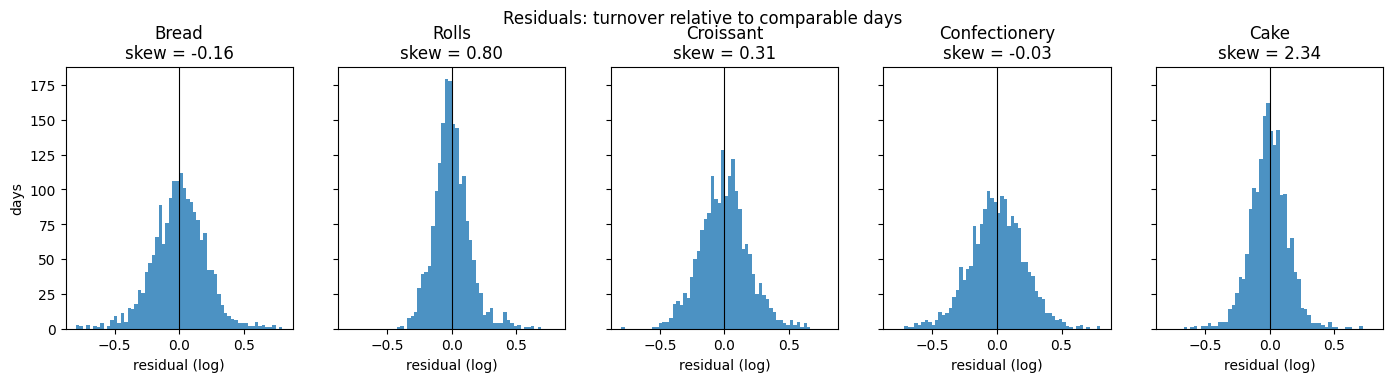

,skewness,upper tail: p95 - median (%),lower tail: median - p5 (%)
group,,,
Bread,-0.16,35.67,28.79
Rolls,0.80,26.99,18.51
Croissant,0.31,38.12,26.09
Confectionery,-0.03,40.19,29.07
Cake,2.34,26.09,20.61


In [3]:
from scipy import stats

fig, axes = plt.subplots(1, 5, figsize=(17, 3.4), sharey=True)
rows = []
for ax, g in zip(axes, CAP_GROUPS):
    r = resid[g].dropna()
    ax.hist(r, bins=60, range=(-0.8, 0.8), color="tab:blue", alpha=0.8)
    ax.axvline(0, color="black", lw=0.8)
    ax.set_title(f"{g}\nskew = {stats.skew(r):.2f}"); ax.set_xlabel("residual (log)")
    q05, q50, q95 = r.quantile([0.05, 0.5, 0.95])
    rows.append({"group": g, "skewness": stats.skew(r),
                 "upper tail: p95 - median (%)": (np.exp(q95 - q50) - 1) * 100,
                 "lower tail: median - p5 (%)": (1 - np.exp(q05 - q50)) * 100})
axes[0].set_ylabel("days")
plt.suptitle("Residuals: turnover relative to comparable days", y=1.05); plt.show()
display(pd.DataFrame(rows).set_index("group").round(2))

---
# Part 2 – How far can the busiest days go?

The table compares the **maximum** of each group with its median and 95th percentile and lists the top days. Most of these peaks are **planned** (New Year's Eve, Easter, summer weekends): the bakery knows them in advance and produces more. They show that production can be scaled up when planned, **not** how much the short-notice buffer can absorb.

In [4]:
rows = []
for g in CAP_GROUPS + ["Seasonal bread"]:
    s = wide[g].dropna()
    rows.append({"group": g, "median (€)": s.median(), "p95 (€)": s.quantile(0.95),
                 "max (€)": s.max(), "max / median": s.max() / s.median(),
                 "max / p95": s.max() / s.quantile(0.95)})
display(pd.DataFrame(rows).set_index("group").round(1))

for g in CAP_GROUPS:
    top = wide[g].nlargest(5)
    print(f"{g}: " + ", ".join(f"{d:%a %Y-%m-%d} ({v:.0f} €)" for d, v in top.items()))

,median (€),p95 (€),max (€),max / median,max / p95
group,,,,,
Bread,120.1,188.0,416.8,3.5,2.2
Rolls,370.8,667.2,1203.4,3.2,1.8
Croissant,142.8,316.6,565.9,4.0,1.8
Confectionery,80.0,153.5,430.5,5.4,2.8
Cake,266.0,394.1,1879.5,7.1,4.8
Seasonal bread,62.9,127.8,172.9,2.7,1.4


Bread: Sat 2018-03-31 (417 €), Sat 2017-04-15 (396 €), Thu 2018-03-29 (370 €), Thu 2017-04-13 (358 €), Mon 2014-05-05 (345 €)
Rolls: Mon 2014-05-05 (1203 €), Sat 2013-08-03 (931 €), Sat 2014-08-09 (875 €), Sun 2013-07-28 (872 €), Sun 2013-08-04 (863 €)
Croissant: Mon 2014-05-05 (566 €), Sat 2013-08-03 (455 €), Mon 2014-08-18 (452 €), Wed 2014-08-06 (446 €), Sat 2014-08-23 (436 €)
Confectionery: Sun 2014-02-23 (431 €), Sun 2014-02-09 (366 €), Sun 2015-02-22 (330 €), Sun 2016-02-21 (320 €), Mon 2014-05-05 (293 €)
Cake: Wed 2014-12-31 (1879 €), Thu 2015-12-31 (1870 €), Sat 2016-12-31 (1705 €), Tue 2013-12-31 (1626 €), Sun 2017-12-31 (1432 €)
